
# Visualisasi Penampang Resistivitas
Notebook ini digunakan untuk membuat plot penampang (pseudosection) resistivitas 2D dari data hasil inversi 1D.
Struktur Folder yang Dibutuhkan:
Pastikan semua file berikut berada dalam satu folder yang sama dengan notebook ini:
vercore.py: File modul inti.
File lokasi stasiun (berisi nama stasiun, koordinat, altitude dalam csv).
Semua file CSV data model inversi per stasiun.


# 1. Import Library
Sel ini berfungsi untuk mengimpor library yang dibutuhkan dan modul core_code yang berisi semua fungsi utama.

In [1]:
import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import core_code2 as core

core_code2.py version 5.1 loaded successfully.


# 2. Konfigurasi Pengguna
Ini adalah satu-satunya sel yang perlu Anda edit.
STATIONS_TO_PLOT: Masukkan nama-nama stasiun yang ingin Anda plot dalam satu penampang.
STATION_LOCATION_FILENAME: Pastikan nama file lokasi stasiun Anda sudah benar.
Pengaturan Plot: Sesuaikan rentang resistivitas, nama palet warna, dan nama file output sesuai keinginan.

In [2]:
BASE_DIR = r"C:\Users\Lenovo X390\Downloads\EDI\EDI\SSQ"
DIR_1D_MODELS = os.path.join(BASE_DIR, "02. PLOT L-CURVE & 1D MODEL")
OUTPUT_DIR = os.path.join(BASE_DIR, "05. PLOT VERTICAL")
os.makedirs(OUTPUT_DIR, exist_ok=True)
PLOT_MODE = 'custom'
STATIONS_TO_PLOT = ['MT1-TE', 'MT2-TE', 'MT3-TE', 'MT4-TE', 'MT5-TE', 'MT6-TE', 'MT7-TE', 'MT8-TE', 'MT9-TE', 'MT10-TE']
USE_LOG_Y_AXIS = False
SHOW_PROFILE_LABELS = True
PROFILE_START_LABEL = 'A'
PROFILE_END_LABEL = "A'"
DEFINE_PROFILE_LINE_MANUALLY = True
PROFILE_LINE_START_STATION = 'MT1'
PROFILE_LINE_END_STATION = 'MT10'
STATION_BAR_WIDTH = 0.008
USE_TOPOGRAPHY = True
Y_LIMITS = (-10, 5)
STATION_LOCATION_FILENAME = os.path.join(BASE_DIR, "04. PLOT HORIZONTAL", "GMT_CALCULATE 1D HORIZONTAL.csv")
LOC_DELIMITER = ','
LOC_STATION_COL = 'Station'
LOC_LATITUDE_COL = 'Latitude'
LOC_LONGITUDE_COL = 'Longitude'
LOC_ELEVATION_COL = 'Elevation'
INV_DEPTH_COL = 'Depth'
INV_RESISTIVITY_COL = 'Log Resistivity'
INV_RMS_COL = 'RMS Error'
RESISTIVITY_MIN = 0
RESISTIVITY_MAX = 10
USE_CUSTOM_COLORMAP = False
CUSTOM_COLORMAP_STYLE = 'smooth'
CUSTOM_COLORS = ['darkred', 'red', 'orange', 'yellow', 'mediumseagreen', 'green', 'cyan', 'blue', 'darkblue']
CUSTOM_BOUNDARIES = [1, 5, 10, 25, 50, 75, 100, 300, 700, 1000]
COLORMAP_NAME = 'jet_r'
LOG_COLOR_SCALE = False
COLORBAR_SHRINK = 0.7
COLORBAR_ASPECT = 10

# 3. Memuat dan Memproses Data Lokasi
Sel ini memanggil fungsi untuk memuat file lokasi, memfilter stasiun sesuai daftar STATIONS_TO_PLOT, dan mengurutkannya berdasarkan latitude.

In [3]:
plot_mode_lower = PLOT_MODE.lower()
sort_by_col = LOC_LONGITUDE_COL if plot_mode_lower == 'longitude' else (LOC_LATITUDE_COL if plot_mode_lower == 'latitude' else 'cumulative_distance')
df_all_locations, sorted_station_df = core.load_and_filter_locations(
    STATION_LOCATION_FILENAME,
    STATIONS_TO_PLOT,
    LOC_STATION_COL,
    sort_by_col,
    LOC_ELEVATION_COL,
    LOC_LATITUDE_COL,
    LOC_LONGITUDE_COL,
    LOC_LONGITUDE_COL,
    LOC_LATITUDE_COL,
    delimiter=LOC_DELIMITER,
    force_custom_order=(plot_mode_lower == 'custom')
)
if sorted_station_df is not None:
    print("\nData 5 stasiun pertama untuk penampang:")
    display(sorted_station_df[[LOC_STATION_COL, LOC_LATITUDE_COL, LOC_LONGITUDE_COL, LOC_ELEVATION_COL]].head())

Stasiun diurutkan berdasarkan daftar kustom. Jarak dihitung sepanjang lintasan.

Data 5 stasiun pertama untuk penampang:


,Station,Latitude,Longitude,Elevation
0,MT1-TE,-7.782639,111.610583,609.015
1,MT1-TE,-7.782639,111.610583,609.015
2,MT1-TE,-7.782639,111.610583,609.015
3,MT1-TE,-7.782639,111.610583,609.015
4,MT1-TE,-7.782639,111.610583,609.015


# 4. Memuat Data Inversi per Stasiun
Sel ini akan memanggil fungsi untuk membaca setiap file CSV stasiun yang relevan (berdasarkan daftar Anda), mengekstrak data resistivitas dan RMS, lalu menggabungkannya menjadi satu tabel besar.

In [4]:
if sorted_station_df is not None:
    current_working_dir = os.getcwd()
    os.chdir(DIR_1D_MODELS)
    print("Menyesuaikan format nama file untuk pembacaan modul...")
    for station in STATIONS_TO_PLOT:
        file_asli = f"{station}_PARAMETER 1D MODEL.csv"
        file_singkat = f"{station}.csv"
        if os.path.exists(file_asli) and not os.path.exists(file_singkat):
            shutil.copy(file_asli, file_singkat)
            print(f"-> Salinan dibuat: {file_singkat}")
    try:
        df_master_data, sorted_station_df_with_rms = core.load_station_inversion_data(
            sorted_station_df,
            LOC_STATION_COL,
            INV_RMS_COL
        )
        if df_master_data is not None:
            print("\nData inversi dari semua stasiun berhasil digabungkan.")
            display(sorted_station_df_with_rms[[LOC_STATION_COL, 'RMS']].head())
    except Exception as e:
        print(f"Terjadi kesalahan saat menggabungkan data: {e}")
    finally:
        os.chdir(current_working_dir)

Menyesuaikan format nama file untuk pembacaan modul...

Data inversi dari semua stasiun berhasil digabungkan.


,Station,RMS
0,MT1-TE,1.34543
1,MT1-TE,1.34543
2,MT1-TE,1.34543
3,MT1-TE,1.34543
4,MT1-TE,1.34543


# 5. Membuat Plot Penampang
Ini adalah langkah terakhir. Sel ini akan menggabungkan semua data yang telah diproses untuk membuat visualisasi akhir—terdiri dari plot RMS di bagian atas dan penampang resistivitas di bagian bawah—lalu menyimpannya sebagai file gambar. Tampilkan dulu peta lokasinya. Gunakan cell di bawahnya jika ingin mebuat tampilan tanpa smooting (sperti colorbar saja).

ModuleNotFoundError: No module named 'contextily'

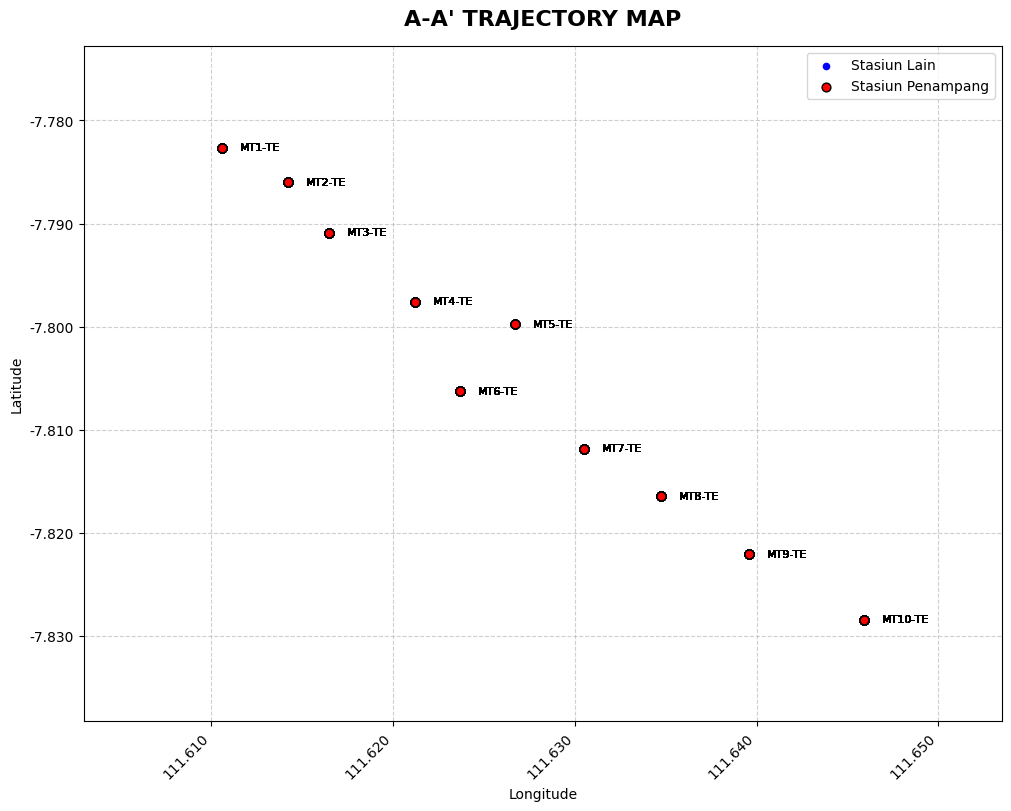

In [5]:
if 'df_all_locations' in locals() and sorted_station_df is not None:
    fig_map, ax_map = plt.subplots(1, 1, figsize=(10, 8), constrained_layout=True)
    core.plot_station_location_map(
        ax_map,
        df_all_locations,
        sorted_station_df_with_rms,
        LOC_LONGITUDE_COL,
        LOC_LATITUDE_COL,
        LOC_STATION_COL,
        show_profile_labels=SHOW_PROFILE_LABELS,
        start_label=PROFILE_START_LABEL,
        end_label=PROFILE_END_LABEL,
        define_manual_line=DEFINE_PROFILE_LINE_MANUALLY,
        start_station_name=PROFILE_LINE_START_STATION,
        end_station_name=PROFILE_LINE_END_STATION
    )
    ax_map.set_title(f"{PROFILE_START_LABEL}-{PROFILE_END_LABEL} TRAJECTORY MAP", fontsize=16, fontweight='bold', pad=15)
    x_min, x_max = ax_map.get_xlim()
    y_min, y_max = ax_map.get_ylim()
    # --- FIX: padding proporsional (persen dari rentang data), bukan angka tetap 0.04 derajat ---
    # supaya peta selalu fit rapat ke lintasan stasiun, berapapun panjang lintasannya
    X_PAD_FRAC = 0.15  # naikkan kalau masih kepotong, turunkan kalau masih kejauhan
    Y_PAD_FRAC = 0.15
    x_pad = (x_max - x_min) * X_PAD_FRAC
    y_pad = (y_max - y_min) * Y_PAD_FRAC
    ax_map.set_xlim(x_min - x_pad, x_max + x_pad)
    ax_map.set_ylim(y_min - y_pad, y_max + y_pad)
    ax_map.set_aspect('auto')  # biarkan sumbu mengisi figure, tidak dipaksa rasio 1:1

    import contextily as cx
    cx.add_basemap(
        ax_map,
        crs="EPSG:4326",  # penting: data lon/lat kita masih WGS84, bukan Web Mercator
        source=cx.providers.Esri.WorldShadedRelief,  # ganti sesuai selera
    )

    handles, labels = ax_map.get_legend_handles_labels()
    new_handles_labels = [(h, l) for h, l in zip(handles, labels) if l != 'Stasiun Lain']
    if new_handles_labels:
        new_handles, new_labels = zip(*new_handles_labels)
        ax_map.legend(new_handles, new_labels, loc='center left', bbox_to_anchor=(1.05, 0.5), borderaxespad=0.)
    for txt in ax_map.texts:
        text_str = txt.get_text().strip()
        if text_str in [f"{PROFILE_START_LABEL}-{PROFILE_END_LABEL} TRAJECTORY MAP", 'Peta Lokasi Stasiun']:
            continue
        x, y = txt.get_position()
        if text_str in [PROFILE_START_LABEL, PROFILE_END_LABEL]:
            txt.set_color('gold')
            txt.set_fontweight('bold')
            txt.set_fontsize(14)
            txt.set_path_effects([pe.withStroke(linewidth=3, foreground='black')])
            if text_str == PROFILE_START_LABEL:
                txt.set_position((x - x_pad * 0.3, y - y_pad * 0.15))
                txt.set_horizontalalignment('right')
            elif text_str == PROFILE_END_LABEL:
                txt.set_position((x - x_pad * 0.15, y + y_pad * 0.15))
                txt.set_horizontalalignment('right')
        else:
            txt.set_position((x + x_pad * 0.1, y))
            txt.set_horizontalalignment('left')
            if text_str == PROFILE_LINE_START_STATION:
                txt.set_position((x + x_pad * 0.2, y))
    map_filename = os.path.join(OUTPUT_DIR, f"{PROFILE_START_LABEL}-{PROFILE_END_LABEL} TRAJECTORY MAP.png")
    plt.savefig(map_filename, dpi=300, bbox_inches='tight')
    print(map_filename)
    plt.show()

In [ ]:
!pip install contextily

# 5.1) Pseudosection 1D Inversion

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter

In [7]:
def calculate_projected_distance(df_stations, start_station, end_station, lon_col, lat_col):
    start_row = df_stations[df_stations[LOC_STATION_COL] == start_station].iloc[0]
    end_row = df_stations[df_stations[LOC_STATION_COL] == end_station].iloc[0]
    p1 = np.array([start_row[lon_col], start_row[lat_col]])
    p2 = np.array([end_row[lon_col], end_row[lat_col]])
    line_vec = p2 - p1
    line_len_sq = np.dot(line_vec, line_vec)
    coords = df_stations[[lon_col, lat_col]].to_numpy()
    t = np.zeros(len(coords)) if line_len_sq == 0 else np.dot(coords - p1, line_vec) / line_len_sq
    return t * np.sqrt(line_len_sq) * 111320.0
def custom_plot_rms(ax, df_stations, station_col):
    rms_values = df_stations['RMS'].values
    x_coords = df_stations['projected_distance_km'].values
    sc = ax.scatter(x_coords, rms_values, c=rms_values, cmap='jet_r', s=80, edgecolor='black', zorder=3)
    cbar = plt.colorbar(sc, ax=ax, pad=0.01, aspect=15)
    cbar.set_label('RMS Values', rotation=90, labelpad=20, fontweight='bold')
    ax.set_title("PLOTTING RMS vs STATION", fontsize=15, fontweight='bold', loc='center', pad=15)
    ax.set_ylabel("RMS Error", fontweight='bold')
    ax.set_xlabel("")
    x_pad = (x_coords.max() - x_coords.min()) * 0.05 if len(x_coords) > 1 else 1
    ax.set_xlim(x_coords.min() - x_pad, x_coords.max() + x_pad)
    ax.set_xticks(x_coords)
    ax.set_xticklabels(df_stations[station_col], rotation=90, fontsize=10, fontweight='normal')
    ax.grid(True, linestyle='--', alpha=0.6, zorder=0)
def custom_plot_1d_stitched(ax, sorted_station_df, df_master, station_col, x_axis_col, elev_col, depth_col, res_col, vmin, vmax, y_limits=None, log_scale=False, cmap_name='jet', use_topo=False):
    ax.set_ylabel('Depth (km)', fontweight='bold')
    cmap = plt.get_cmap(cmap_name)
    norm = mcolors.LogNorm(vmin=vmin, vmax=vmax) if log_scale else mcolors.Normalize(vmin=vmin, vmax=vmax)
    stasiun_x_km = sorted_station_df['projected_distance_km'].values
    stasiun_y_km = sorted_station_df[elev_col].values / 1000.0 if use_topo else np.zeros(len(sorted_station_df))
    bar_width = max(0.2, (stasiun_x_km.max() - stasiun_x_km.min()) * 0.03) if len(stasiun_x_km) > 1 else 0.5
    for _, row in sorted_station_df.iterrows():
        s_name, x_pos = row[station_col], row['projected_distance_km']
        elev = row[elev_col] / 1000.0 if use_topo else 0.0
        df_s = df_master[df_master[station_col] == s_name].sort_values(depth_col)
        # --- FIX: buang air layer (depth < 0, mis. depth = -10000 dari file starting model Occam1D) ---
        df_s = df_s[df_s[depth_col] >= 0]
        if df_s.empty: continue
        depths = df_s[depth_col].values / 1000.0
        res_vals = df_s[res_col].values
        thickness = np.diff(depths) if len(depths) > 1 else [5.0]
        bottoms = np.append(depths[1:], depths[-1] + thickness[-1])
        colors = cmap(norm(res_vals))
        tops_y = elev - depths if use_topo else depths
        bottoms_y = elev - bottoms if use_topo else bottoms
        # --- FIX: jaga-jaga supaya bar tidak pernah "menembus" ke atas topografi ---
        if use_topo:
            tops_y = np.minimum(tops_y, elev)
        heights = tops_y - bottoms_y if use_topo else bottoms_y - tops_y
        ax.bar(x=x_pos, height=heights, bottom=bottoms_y if use_topo else tops_y, width=bar_width, color=colors, align='center', edgecolor='none')
    if y_limits is not None:
        ax.set_ylim(y_limits[0], stasiun_y_km.max() + 1.0)
    if not use_topo and not ax.yaxis_inverted():
        ax.invert_yaxis()
    ax.set_xlabel("Distance (km)", fontweight='bold')
    x_pad = (stasiun_x_km.max() - stasiun_x_km.min()) * 0.05 if len(stasiun_x_km) > 1 else 1
    ax.set_xlim(stasiun_x_km.min() - x_pad, stasiun_x_km.max() + x_pad)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos: f"{abs(val):.1f}"))
    ax.set_title("1D INVERSION MODEL", fontsize=15, fontweight='bold', loc='center', pad=20)
    ax.text(0.01, 1.0, "A", transform=ax.transAxes, fontsize=14, fontweight='bold', ha='left', va='bottom')
    ax.text(0.99, 1.0, "A'", transform=ax.transAxes, fontsize=14, fontweight='bold', ha='right', va='bottom')
    ax.plot(stasiun_x_km, stasiun_y_km, linestyle='-', color='black', linewidth=1.5, zorder=3)
    ax.plot(stasiun_x_km, stasiun_y_km, marker='v', color='black', markerfacecolor='red', markersize=8, linestyle='None', zorder=4)
    for sx, sy, sname in zip(stasiun_x_km, stasiun_y_km, sorted_station_df[station_col]):
        ax.text(sx, sy + 0.2, sname, rotation=90, fontsize=9, fontweight='normal', ha='center', va='bottom', zorder=5)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.01, aspect=15)
    cbar.set_label('Log$_{10}$ Resistivity ($\Omega \cdot$m)', rotation=90, labelpad=20, fontweight='bold')

In [8]:
for s in ['MT4', 'MT5', 'MT6', 'MT8']:
    sub = df_master_data[df_master_data[LOC_STATION_COL] == s]
    print(s, "min/max Log Resistivity:", sub[INV_RESISTIVITY_COL].min(), sub[INV_RESISTIVITY_COL].max())
    print(s, "jumlah layer:", len(sub), "max depth:", sub[INV_DEPTH_COL].max())

KeyError: 'Log Resistivity'


Menghitung proyeksi jarak garis lintasan A-A'...
✅ Titik 0 (Distance) berhasil dikunci pada stasiun MT6.
🔍 Mendiagnosis nama kolom di dalam data master...

Sedang merender model inversi 1D vertikal...
✅ Plot berhasil dirender dengan cepat!
📁 File tersimpan di: C:\Users\Lenovo X390\Downloads\EDI\EDI\RAW EDI\AMT\05. PLOT VERTICAL\A-A' 1D INVERSION MODEL.png


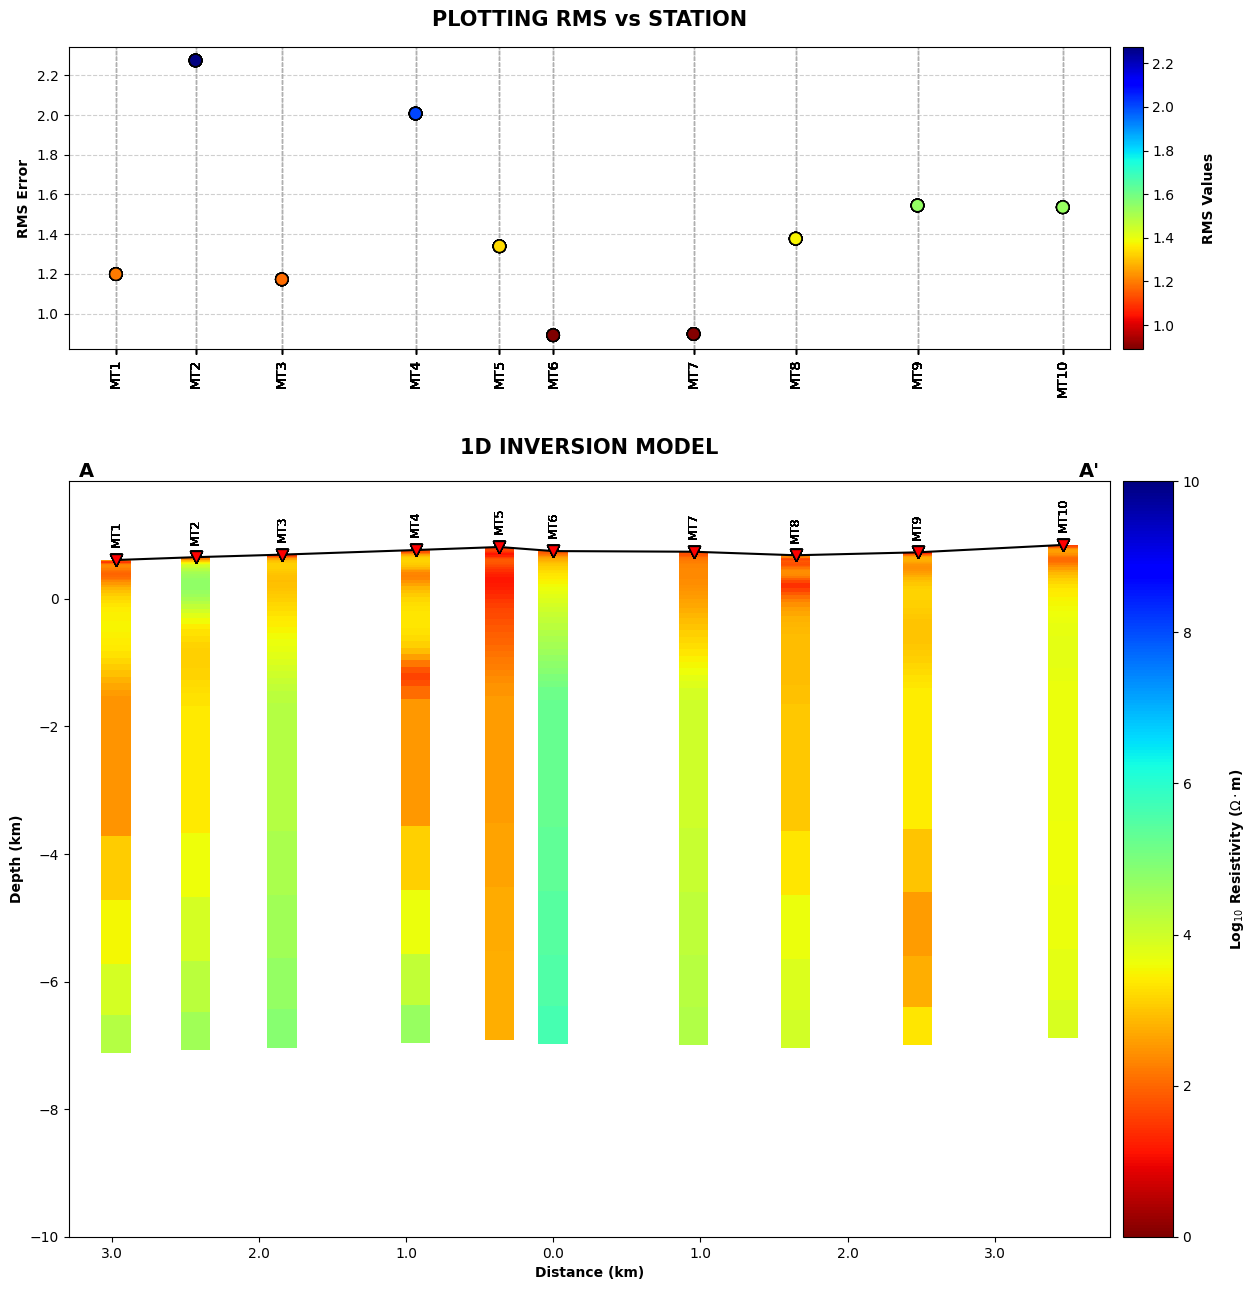

In [9]:
if 'df_master_data' in locals() and df_master_data is not None:
    print("\nMenghitung proyeksi jarak garis lintasan A-A'...")
    projected_dist_m = calculate_projected_distance(sorted_station_df_with_rms, PROFILE_LINE_START_STATION, PROFILE_LINE_END_STATION, LOC_LONGITUDE_COL, LOC_LATITUDE_COL)
    sorted_station_df_with_rms['projected_distance_km'] = projected_dist_m / 1000.0
    if 'MT6' in sorted_station_df_with_rms[LOC_STATION_COL].values:
        mt6_dist = sorted_station_df_with_rms.loc[sorted_station_df_with_rms[LOC_STATION_COL] == 'MT6', 'projected_distance_km'].values[0]
        sorted_station_df_with_rms['projected_distance_km'] -= mt6_dist
        print("✅ Titik 0 (Distance) berhasil dikunci pada stasiun MT6.")
    else:
        print("⚠️ Peringatan: Stasiun 'MT6' tidak ditemukan. Titik 0 menggunakan awal lintasan.")
    sorted_station_df_with_rms = sorted_station_df_with_rms.sort_values('projected_distance_km').reset_index(drop=True)
    print("🔍 Mendiagnosis nama kolom di dalam data master...")
    kolom_tersedia = df_master_data.columns.tolist()
    if INV_RESISTIVITY_COL not in kolom_tersedia:
        calon_kolom = ['Log Resistivity', 'Log Resistivity (Ohm.m)', 'Log_Resistivity', 'Resistivity', 'Resistivity (Ohm.m)', 'Rho', 'Res_DET', 'Res_XY', 'Res_YX']
        kolom_ditemukan = next((col for col in calon_kolom if col in kolom_tersedia), None)
        if kolom_ditemukan:
            if 'log' not in kolom_ditemukan.lower():
                df_master_data['Auto_Log_Res'] = np.log10(np.where(df_master_data[kolom_ditemukan] > 0, df_master_data[kolom_ditemukan], np.nan))
                INV_RESISTIVITY_COL = 'Auto_Log_Res'
            else:
                INV_RESISTIVITY_COL = kolom_ditemukan
        else:
            raise KeyError("❌ Gagal menemukan kolom Resistivitas di CSV Anda.")
    fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 14), gridspec_kw={'height_ratios': [1, 2.5]})
    custom_plot_rms(ax=axs[0], df_stations=sorted_station_df_with_rms, station_col=LOC_STATION_COL)
    print("\nSedang merender model inversi 1D vertikal...")
    custom_plot_1d_stitched(
        ax=axs[1], sorted_station_df=sorted_station_df_with_rms, df_master=df_master_data,
        station_col=LOC_STATION_COL, x_axis_col=sort_by_col, elev_col=LOC_ELEVATION_COL,
        depth_col=INV_DEPTH_COL, res_col=INV_RESISTIVITY_COL, vmin=RESISTIVITY_MIN,
        vmax=RESISTIVITY_MAX, y_limits=Y_LIMITS, log_scale=LOG_COLOR_SCALE,
        cmap_name=COLORMAP_NAME, use_topo=USE_TOPOGRAPHY
    )
    plt.subplots_adjust(hspace=0.25, top=0.95, bottom=0.1)
    OUTPUT_IMAGE_FILENAME = os.path.join(OUTPUT_DIR, "A-A' 1D INVERSION MODEL.png")
    os.makedirs(os.path.dirname(OUTPUT_IMAGE_FILENAME), exist_ok=True)
    plt.savefig(OUTPUT_IMAGE_FILENAME, dpi=200, bbox_inches='tight')
    print("✅ Plot berhasil dirender dengan cepat!\n📁 File tersimpan di:", OUTPUT_IMAGE_FILENAME)
    plt.show()
else:
    print("❌ Error: Variabel 'df_master_data' tidak ditemukan atau kosong.")

# 5.2) Pseudosection 2D

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter

In [11]:
def calculate_projected_distance(df_stations, start_station, end_station, lon_col, lat_col):
    start_row = df_stations[df_stations[LOC_STATION_COL] == start_station].iloc[0]
    end_row = df_stations[df_stations[LOC_STATION_COL] == end_station].iloc[0]
    p1 = np.array([start_row[lon_col], start_row[lat_col]])
    p2 = np.array([end_row[lon_col], end_row[lat_col]])
    line_vec = p2 - p1
    line_len_sq = np.dot(line_vec, line_vec)
    coords = df_stations[[lon_col, lat_col]].to_numpy()
    t = np.zeros(len(coords)) if line_len_sq == 0 else np.dot(coords - p1, line_vec) / line_len_sq
    return t * np.sqrt(line_len_sq) * 111320.0
def custom_plot_rms(ax, df_stations, station_col):
    rms_values = df_stations['RMS'].values
    x_coords = df_stations['projected_distance_km'].values
    sc = ax.scatter(x_coords, rms_values, c=rms_values, cmap='jet_r', s=80, edgecolor='black', zorder=3)
    cbar = plt.colorbar(sc, ax=ax, pad=0.01, aspect=15)
    cbar.set_label('RMS Values', rotation=90, labelpad=20, fontweight='bold')
    ax.set_title("PLOTTING RMS vs STATION", fontsize=15, fontweight='bold', loc='center', pad=15)
    ax.set_ylabel("RMS Error", fontweight='bold')
    ax.set_xlabel("")
    x_pad = (x_coords.max() - x_coords.min()) * 0.05 if len(x_coords) > 1 else 1
    ax.set_xlim(x_coords.min() - x_pad, x_coords.max() + x_pad)
    ax.set_xticks(x_coords)
    ax.set_xticklabels(df_stations[station_col], rotation=90, fontsize=10, fontweight='normal')
    ax.grid(True, linestyle='--', alpha=0.6, zorder=0)
def custom_plot_pseudosection(ax, sorted_station_df, df_master, station_col, x_axis_col, elev_col, depth_col, res_col, vmin, vmax, y_limits=None, log_scale=False, cmap_name='jet', use_topo=False):
    # --- FIX: buang air layer (depth < 0, mis. depth = -10000 dari file starting model Occam1D) ---
    df_master = df_master[df_master[depth_col] >= 0]
    df_merged = pd.merge(df_master, sorted_station_df[[station_col, 'projected_distance_km', elev_col]], on=station_col, how='inner').dropna(subset=['projected_distance_km', depth_col, res_col])
    X_km = df_merged['projected_distance_km'].values
    Z_res = df_merged[res_col].values
    Y_km = (df_merged[elev_col].values - df_merged[depth_col].values) / 1000.0 if use_topo else df_merged[depth_col].values / 1000.0
    ax.set_ylabel('Depth (km)', fontweight='bold')
    cmap = plt.get_cmap(cmap_name)
    if log_scale:
        safe_vmin = max(vmin, 0.1)
        norm = mcolors.LogNorm(vmin=safe_vmin, vmax=vmax)
        levels = np.logspace(np.log10(safe_vmin), np.log10(vmax), 50)
    else:
        norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
        levels = np.linspace(vmin, vmax, 50)
    img = ax.tricontourf(X_km, Y_km, Z_res, levels=levels, cmap=cmap, norm=norm)
    stasiun_y_km = sorted_station_df[elev_col].values / 1000.0 if use_topo else np.zeros(len(sorted_station_df))
    if y_limits is not None:
        ax.set_ylim(y_limits[0], stasiun_y_km.max() + 1.0)
    if not use_topo and not ax.yaxis_inverted():
        ax.invert_yaxis()
    ax.set_xlabel("Distance (km)", fontweight='bold')
    stasiun_x_km = sorted_station_df['projected_distance_km'].values
    x_pad = (stasiun_x_km.max() - stasiun_x_km.min()) * 0.05 if len(stasiun_x_km) > 1 else 1
    ax.set_xlim(stasiun_x_km.min() - x_pad, stasiun_x_km.max() + x_pad)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos: f"{abs(val):.1f}"))
    ax.set_title("PSEUDOSECTION RESISTIVITY 2D FROM 1D INVERSION", fontsize=15, fontweight='bold', loc='center', pad=20)
    ax.text(0.01, 1.0, "A", transform=ax.transAxes, fontsize=14, fontweight='bold', ha='left', va='bottom')
    ax.text(0.99, 1.0, "A'", transform=ax.transAxes, fontsize=14, fontweight='bold', ha='right', va='bottom')
    ax.plot(stasiun_x_km, stasiun_y_km, linestyle='-', color='black', linewidth=1.5, zorder=3)
    ax.plot(stasiun_x_km, stasiun_y_km, marker='v', color='black', markerfacecolor='red', markersize=8, linestyle='None', zorder=4)
    for sx, sy, sname in zip(stasiun_x_km, stasiun_y_km, sorted_station_df[station_col]):
        ax.text(sx, sy + 2, sname, rotation=90, fontsize=9, ha='center', va='bottom', zorder=5)
    cbar = plt.colorbar(img, ax=ax, pad=0.01, aspect=15)
    cbar.set_label('Log$_{10}$ Resistivity ($\Omega \cdot$m)', rotation=90, labelpad=20, fontweight='bold')


Menghitung proyeksi jarak garis lintasan A-A'...
⚠️ Peringatan: Stasiun 'HLC3' tidak ditemukan. Titik 0 menggunakan awal lintasan.
🔍 Mendiagnosis nama kolom di dalam data master...
🔄 Kolom Resistivitas asli terdeteksi, melakukan perhitungan konversi ke Log10 otomatis.

Sedang merender pseudosection 2D...
✅ Plot berhasil dirender dengan cepat!
📁 File tersimpan di: C:\Users\Lenovo X390\Downloads\EDI\EDI\RAW EDI\AMT\05. PLOT VERTICAL\A-A' 2D PSEUDOSECTION VERTICAL MAP.png


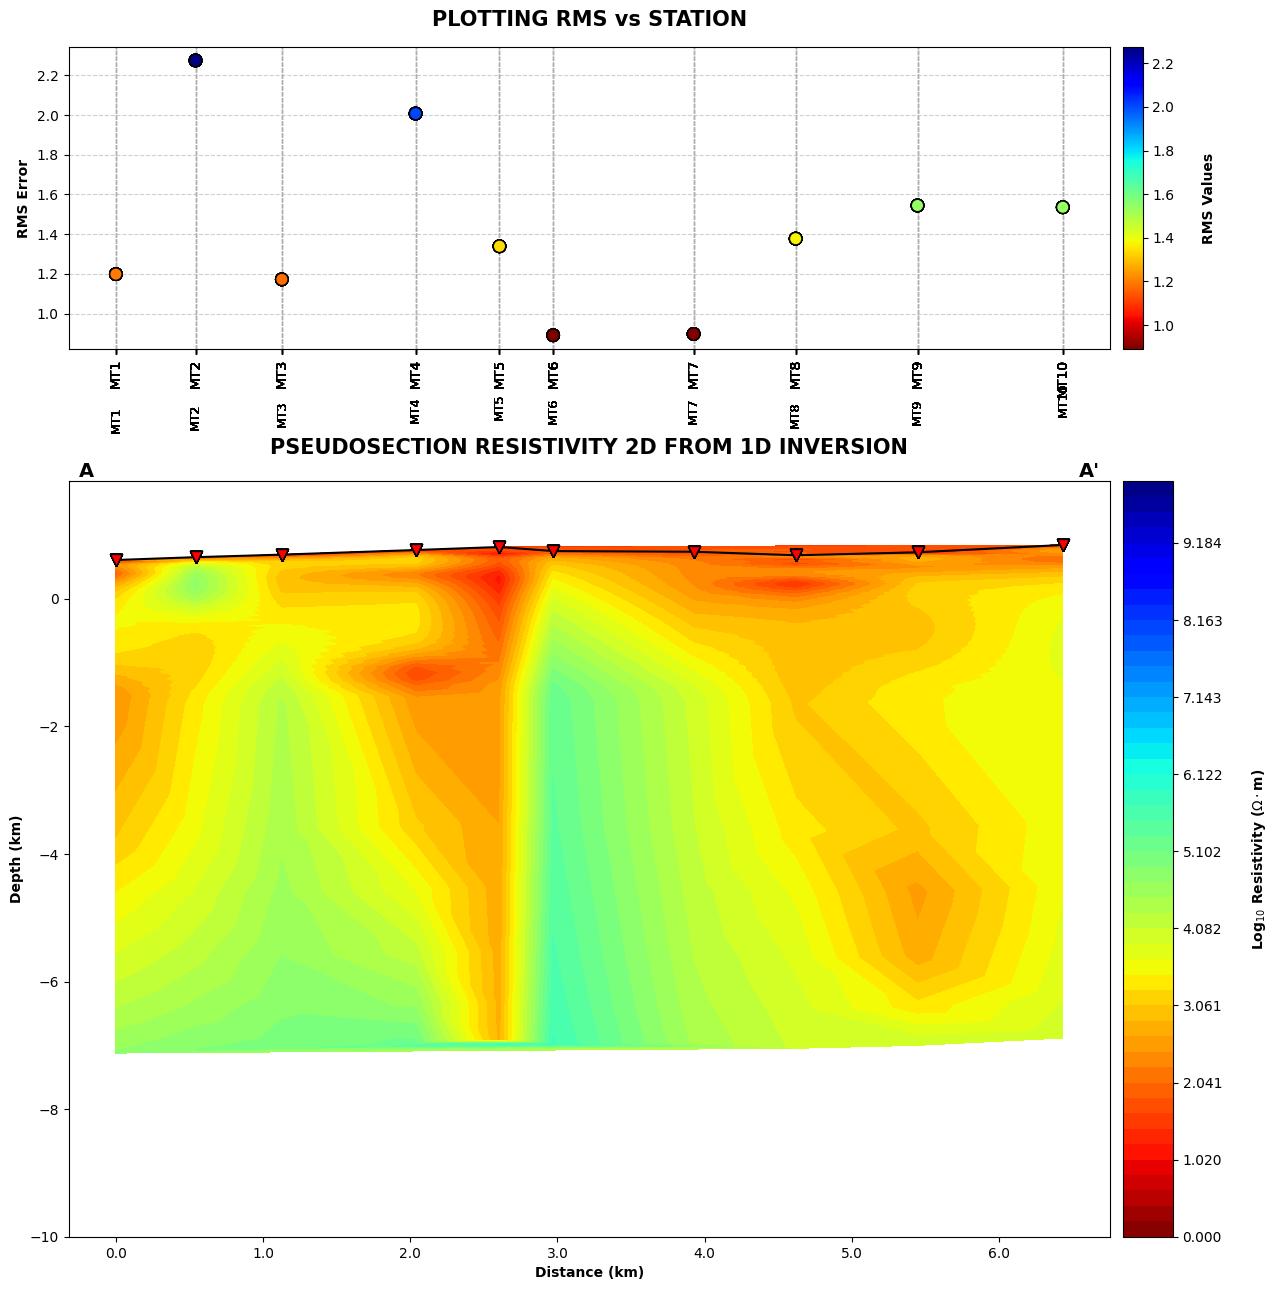

In [12]:
if 'df_master_data' in locals() and df_master_data is not None:
    print("\nMenghitung proyeksi jarak garis lintasan A-A'...")
    sorted_station_df_with_rms['projected_distance_km'] = calculate_projected_distance(sorted_station_df_with_rms, PROFILE_LINE_START_STATION, PROFILE_LINE_END_STATION, LOC_LONGITUDE_COL, LOC_LATITUDE_COL) / 1000.0
    if 'HLC3' in sorted_station_df_with_rms[LOC_STATION_COL].values:
        sorted_station_df_with_rms['projected_distance_km'] -= sorted_station_df_with_rms.loc[sorted_station_df_with_rms[LOC_STATION_COL] == 'HLC3', 'projected_distance_km'].values[0]
        print("✅ Titik 0 (Distance) berhasil dikunci pada stasiun HLC3.")
    else:
        print("⚠️ Peringatan: Stasiun 'HLC3' tidak ditemukan. Titik 0 menggunakan awal lintasan.")
    sorted_station_df_with_rms = sorted_station_df_with_rms.sort_values('projected_distance_km').reset_index(drop=True)
    print("🔍 Mendiagnosis nama kolom di dalam data master...")
    kolom_tersedia = df_master_data.columns.tolist()
    calon_kolom = ['Log Resistivity', 'Log Resistivity (Ohm.m)', 'Log_Resistivity', 'Resistivity', 'Resistivity (Ohm.m)', 'Rho', 'Res_DET', 'Res_XY', 'Res_YX']
    kolom_ditemukan = next((col for col in calon_kolom if col in kolom_tersedia), None)
    if kolom_ditemukan:
        if 'log' not in kolom_ditemukan.lower():
            df_master_data['Auto_Log_Res'] = np.log10(np.where(df_master_data[kolom_ditemukan] > 0, df_master_data[kolom_ditemukan], np.nan))
            INV_RESISTIVITY_COL = 'Auto_Log_Res'
            print("🔄 Kolom Resistivitas asli terdeteksi, melakukan perhitungan konversi ke Log10 otomatis.")
        else:
            INV_RESISTIVITY_COL = kolom_ditemukan
    else:
        raise KeyError("❌ Gagal menemukan kolom Resistivitas di CSV Anda.")
    fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 14), gridspec_kw={'height_ratios': [1, 2.5]})
    custom_plot_rms(ax=axs[0], df_stations=sorted_station_df_with_rms, station_col=LOC_STATION_COL)
    print("\nSedang merender pseudosection 2D...")
    custom_plot_pseudosection(
        ax=axs[1], sorted_station_df=sorted_station_df_with_rms, df_master=df_master_data,
        station_col=LOC_STATION_COL, x_axis_col=sort_by_col, elev_col=LOC_ELEVATION_COL,
        depth_col=INV_DEPTH_COL, res_col=INV_RESISTIVITY_COL, vmin=RESISTIVITY_MIN,
        vmax=RESISTIVITY_MAX, y_limits=Y_LIMITS, log_scale=LOG_COLOR_SCALE,
        cmap_name=COLORMAP_NAME, use_topo=USE_TOPOGRAPHY
    )
    plt.subplots_adjust(hspace=0.25, top=0.95, bottom=0.1)
    OUTPUT_IMAGE_FILENAME = os.path.join(OUTPUT_DIR, "A-A' 2D PSEUDOSECTION VERTICAL MAP.png")
    os.makedirs(os.path.dirname(OUTPUT_IMAGE_FILENAME), exist_ok=True)
    plt.savefig(OUTPUT_IMAGE_FILENAME, dpi=200, bbox_inches='tight')
    print("✅ Plot berhasil dirender dengan cepat!\n📁 File tersimpan di:", OUTPUT_IMAGE_FILENAME)
    plt.show()
else:
    print("❌ Error: Variabel 'df_master_data' tidak ditemukan atau kosong.")